In [ ]:
import cv2
import numpy as np
!pip install mtcnn
from mtcnn import MTCNN
# Initialize MTCNN detector
detector = MTCNN()

# Load image
image = cv2.imread('/content/face_image.jpeg')
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Detect faces
faces = detector.detect_faces(image_rgb)

# Process detection results
for face in faces:
    x, y, width, height = face['box']

    # Draw rectangle around face (for visualization)
    cv2.rectangle(image, (x, y), (x+width, y+height), (0, 255, 0), 2)

    # Extract face region for next processing steps
    face_region = image[y:y+height, x:x+width]

    # Save or process the face region
    cv2.imwrite('detected_face.jpg', face_region)

# Display result (optional)
# cv2.imshow('Detected Face', image)
# cv2.waitKey(0)
# cv2.destroyAllWindows()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 63.5 MB/s eta 0:00:00


In [ ]:
!pip install opencv-python
!pip install dlib
!pip install numpy
!pip install scikit-image

In [ ]:
!wget http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2
!bzip2 -d shape_predictor_68_face_landmarks.dat.bz2

--2025-04-15 12:57:09--  http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2
Resolving dlib.net (dlib.net)... 107.180.26.78
Connecting to dlib.net (dlib.net)|107.180.26.78|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2 [following]
--2025-04-15 12:57:09--  https://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2
Connecting to dlib.net (dlib.net)|107.180.26.78|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 64040097 (61M)
Saving to: ‘shape_predictor_68_face_landmarks.dat.bz2’

shape_predictor_68_ 100%[===================>]  61.07M  33.8MB/s    in 1.8s    

2025-04-15 12:57:11 (33.8 MB/s) - ‘shape_predictor_68_face_landmarks.dat.bz2’ saved [64040097/64040097]

bzip2: Output file shape_predictor_68_face_landmarks.dat already exists.


In [ ]:
import cv2
import dlib
import numpy as np
# Initialize dlib's face detector and facial landmark predictor

detector = dlib.get_frontal_face_detector()

predictor = dlib.shape_predictor("/content/shape_predictor_68_face_landmarks.dat")  # Download this file from dlib website

# Load the face image (assuming you have it from previous step)

face_image = cv2.imread("detected_face.jpg")

gray = cv2.cvtColor(face_image, cv2.COLOR_BGR2GRAY)

# Detect faces

faces = detector(gray)

# Process each face

for face in faces:

    # Get facial landmarks

    landmarks = predictor(gray, face)



    # Extract eye landmarks

    # Left eye points are landmarks 36-41

    # Right eye points are landmarks 42-47

    left_eye_pts = np.array([(landmarks.part(i).x, landmarks.part(i).y) for i in range(36, 42)])

    right_eye_pts = np.array([(landmarks.part(i).x, landmarks.part(i).y) for i in range(42, 48)])



    # Get eye bounding boxes with some padding

    padding = 10  # Adjust based on your needs



    # Left eye bounding box

    left_x_min = np.min(left_eye_pts[:, 0]) - padding

    left_y_min = np.min(left_eye_pts[:, 1]) - padding

    left_x_max = np.max(left_eye_pts[:, 0]) + padding

    left_y_max = np.max(left_eye_pts[:, 1]) + padding



    # Right eye bounding box

    right_x_min = np.min(right_eye_pts[:, 0]) - padding

    right_y_min = np.min(right_eye_pts[:, 1]) - padding

    right_x_max = np.max(right_eye_pts[:, 0]) + padding

    right_y_max = np.max(right_eye_pts[:, 1]) + padding



    # Extract eye regions

    left_eye_region = face_image[left_y_min:left_y_max, left_x_min:left_x_max]

    right_eye_region = face_image[right_y_min:right_y_max, right_x_min:right_x_max]



    # Save the eye regions

    cv2.imwrite("left_eye.jpg", left_eye_region)

    cv2.imwrite("right_eye.jpg", right_eye_region)



    # For visualization (optional)

    cv2.rectangle(face_image, (left_x_min, left_y_min), (left_x_max, left_y_max), (0, 255, 0), 2)

    cv2.rectangle(face_image, (right_x_min, right_y_min), (right_x_max, right_y_max), (0, 255, 0), 2)



    # Draw all eye landmarks

    for (x, y) in left_eye_pts:

        cv2.circle(face_image, (x, y), 1, (0, 0, 255), -1)

    for (x, y) in right_eye_pts:

        cv2.circle(face_image, (x, y), 1, (0, 0, 255), -1)

# Display result (optional)

# cv2.imshow("Eyes Detected", face_image)

# cv2.waitKey(0)

# cv2.destroyAllWindows()

In [ ]:
import cv2
import numpy as np

# Load the eye image
eye_image = cv2.imread("left_eye.jpg")

# Check if image was loaded successfully
if eye_image is None:
    print("Error: Could not load image. Check file path and image format.")
else:
    original_image = eye_image.copy()
    height, width = eye_image.shape[:2]
    print(f"Image dimensions: width={width}, height={height}")

    # 1. Convert to grayscale
    eye_gray = cv2.cvtColor(eye_image, cv2.COLOR_BGR2GRAY)

    # 2. Apply Gaussian blur to reduce noise
    blurred = cv2.GaussianBlur(eye_gray, (7, 7), 0)

    # 3. Apply histogram equalization to enhance contrast
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(blurred)

    # 4. Detect iris using Hough Circle Transform
    iris_circles = None
    iris_params = [
        # dp, minDist, param1, param2, minRadius, maxRadius
        [1.5, 30, 80, 20, 15, 40],  # Adjusted for smaller iris
        [1.2, 25, 60, 15, 10, 50],
        [1.8, 35, 70, 18, 20, 45]
    ]

    for dp, minDist, param1, param2, minRadius, maxRadius in iris_params:
        detected_circles = cv2.HoughCircles(
            enhanced,
            cv2.HOUGH_GRADIENT,
            dp=dp,
            minDist=minDist,
            param1=param1,
            param2=param2,
            minRadius=minRadius,
            maxRadius=maxRadius
        )
        if detected_circles is not None:
            iris_circles = detected_circles
            break

    if iris_circles is not None:
        iris_circles = np.round(iris_circles).astype(np.int32)
        x_iris, y_iris, r_iris = iris_circles[0, 0]
        print(f"Detected iris: center=({x_iris}, {y_iris}), radius={r_iris}")

        # 5. Detect pupil (smaller circle within iris)
        pupil_circles = None
        pupil_params = [
            # dp, minDist, param1, param2, minRadius, maxRadius
            [1.5, 20, 80, 15, 5, int(r_iris * 0.5)],  # Pupil is smaller than iris
            [1.2, 15, 60, 10, 5, int(r_iris * 0.6)],
            [1.8, 25, 70, 12, 5, int(r_iris * 0.4)]
        ]

        for dp, minDist, param1, param2, minRadius, maxRadius in pupil_params:
            detected_pupil = cv2.HoughCircles(
                enhanced,
                cv2.HOUGH_GRADIENT,
                dp=dp,
                minDist=minDist,
                param1=param1,
                param2=param2,
                minRadius=minRadius,
                maxRadius=maxRadius
            )
            if detected_pupil is not None:
                pupil_circles = detected_pupil
                break

        if pupil_circles is not None:
            pupil_circles = np.round(pupil_circles).astype(np.int32)
            x_pupil, y_pupil, r_pupil = pupil_circles[0, 0]
            print(f"Detected pupil: center=({x_pupil}, {y_pupil}), radius={r_pupil}")

            # Ensure pupil is inside iris
            if abs(x_iris - x_pupil) > 5 or abs(y_iris - y_pupil) > 5 or r_pupil >= r_iris:
                print("Pupil detection invalid, using estimated pupil radius.")
                r_pupil = int(r_iris * 0.4)
                x_pupil, y_pupil = x_iris, y_iris

            # Create iris mask (donut shape: iris minus pupil)
            iris_mask = np.zeros_like(eye_gray)
            cv2.circle(iris_mask, (x_iris, y_iris), r_iris, 255, -1)
            pupil_mask = np.zeros_like(eye_gray)
            cv2.circle(pupil_mask, (x_pupil, y_pupil), r_pupil, 255, -1)
            final_mask = cv2.subtract(iris_mask, pupil_mask)

            # Apply mask to isolate iris
            iris_only = cv2.bitwise_and(original_image, original_image, mask=final_mask)

            # Crop tightly around the iris
            padding = 2
            x_min = int(max(0, x_iris - r_iris - padding))
            x_max = int(min(width, x_iris + r_iris + padding))
            y_min = int(max(0, y_iris - r_iris - padding))
            y_max = int(min(height, y_iris + r_iris + padding))

            print(f"Crop coordinates: x_min={x_min}, x_max={x_max}, y_min={y_min}, y_max={y_max}")

            if x_max <= x_min or y_max <= y_min:
                print("Invalid crop dimensions.")
            else:
                iris_crop = iris_only[y_min:y_max, x_min:x_max]

                if iris_crop.size == 0 or iris_crop.shape[0] == 0 or iris_crop.shape[1] == 0:
                    print("Error: Cropped image is empty.")
                else:
                    # Normalize iris to rectangular form (unwrap the donut shape)
                    # Create a polar-to-cartesian mapping
                    output_width = 360  # Angular resolution
                    output_height = r_iris - r_pupil  # Radial resolution
                    normalized_iris = np.zeros((output_height, output_width, 3), dtype=np.uint8)

                    for i in range(output_width):
                        theta = (i / output_width) * 2 * np.pi
                        for j in range(output_height):
                            r = r_pupil + j
                            x = int(x_iris + r * np.cos(theta))
                            y = int(y_iris + r * np.sin(theta))
                            if 0 <= x < width and 0 <= y < height:
                                normalized_iris[j, i] = iris_only[y, x]

                    # Enhance colors and texture
                    lab = cv2.cvtColor(normalized_iris, cv2.COLOR_BGR2LAB)
                    l, a, b = cv2.split(lab)
                    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
                    l_enhanced = clahe.apply(l)
                    # Boost color channels for vibrant effect
                    a = cv2.convertScaleAbs(a, alpha=1.5, beta=0)
                    b = cv2.convertScaleAbs(b, alpha=1.5, beta=0)
                    enhanced_lab = cv2.merge((l_enhanced, a, b))
                    enhanced_iris = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2BGR)

                    # Save the result
                    cv2.imwrite("iris_only.jpg", enhanced_iris)
                    print("Iris extracted and normalized successfully")
        else:
            print("No pupil detected - try adjusting pupil parameters")
    else:
        print("No iris detected - try adjusting Hough parameters")

Image dimensions: width=90, height=45
Detected iris: center=(34, 41), radius=34
Crop coordinates: x_min=0, x_max=70, y_min=5, y_max=45
Iris extracted successfully


In [ ]:
!git clone https://github.com/facebookresearch/segment-anything.git
%cd segment-anything
!pip install -q -e .

Cloning into 'segment-anything'...
remote: Enumerating objects: 304, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 304 (delta 2), reused 1 (delta 1), pack-reused 299 (from 2)
Receiving objects: 100% (304/304), 18.31 MiB | 25.90 MiB/s, done.
Resolving deltas: 100% (159/159), done.
/content/segment-anything
  Preparing metadata (setup.py) ... done


In [ ]:
!wget -c https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth

--2025-04-15 07:51:13--  https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 18.173.166.74, 18.173.166.48, 18.173.166.31, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|18.173.166.74|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2564550879 (2.4G) [binary/octet-stream]
Saving to: ‘sam_vit_h_4b8939.pth’

sam_vit_h_4b8939.pt 100%[===================>]   2.39G  90.8MB/s    in 27s     

2025-04-15 07:51:41 (90.0 MB/s) - ‘sam_vit_h_4b8939.pth’ saved [2564550879/2564550879]



In [ ]:
import cv2
import numpy as np
from segment_anything import sam_model_registry, SamPredictor
import torch

image_path = "/content/right_eye.jpg"
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

sam = sam_model_registry["vit_h"](checkpoint="sam_vit_h_4b8939.pth")
predictor = SamPredictor(sam)
predictor.set_image(image_rgb)


In [ ]:
h, w, _ = image.shape
input_point = np.array([[w // 2, h // 2]])
input_label = np.array([1])

masks, scores, logits = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    multimask_output=True
)

mask = masks[0].astype(np.uint8)


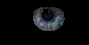

In [ ]:
# Extract the iris region
iris_only = cv2.bitwise_and(image, image, mask=mask)

# Save and show
output_path = "/content/iris_extracted1.png"
cv2.imwrite(output_path, iris_only)

from IPython.display import Image, display
display(Image(output_path))
